In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("../..")

import scipy.sparse as sps
from scipy.sparse.linalg import cg as sp_cg

import pandas as pd

from trips.test_problems.Tomography import Tomography
import astra

import jlinops

import numpy as np
import math

from jlinops.base import _CustomLinearOperator
# from .util import get_device

# from ias import IASSolver

from trips.utilities.phantoms import shepp_logan

from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import FormatStrFormatter

import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec
# mpl.rcParams['text.usetex'] = True
# mpl.rc('text.latex', preamble=r'\usepackage{amsmath}')

# Define the custom style with RGB color values
custom_style = {
    "axes.prop_cycle": plt.cycler(color=[(106/255, 192/255, 205/255),  # blue - C0
                                         (235/255, 186/255, 63/255),  # gold - C1
                                         (172/255, 46/255, 55/255),  # red - C2
                                         (32/255, 82/255, 145/255),  # dark blue - C3
                                         (83/255, 165/255, 106/255),  # green - C4
                                         (239/255, 145/255, 75/255),  # orange - C5
                                         (208/255, 92/255, 89/255),  # pink - C6
                                         (80/255, 67/255, 157/255),  # purple - C7
                                         (82/255, 82/255, 82/255),  # gray - C8
                                         (53/255, 53/255, 53/255),  # charcoal - C9
                                         (30/255, 27/255, 28/255), # black - C10  
                                         ]) 
}
plt.rc('axes', prop_cycle=custom_style['axes.prop_cycle'])

method_markers = {
    "GKS": "o",
    "S-GKS": "o",
    "resS-GKS": "v",
    "recS-GKS": "^",
    "PS-GKS": "o",
    "resPS-GKS": "v",
    "recPS-GKS": "^",
    "PS-GKB": "o",
    "FGK": "o",
    "FLSQR-I": "$\\text{I}$",
    "FLSQR-R": "$\\text{R}$",
    "FLSQR-W": "$*$",
    "IRW-FLSQR": "x",
}

method_colors = {
    "GKS": "C1",
    "S-GKS": "C4",
    "resS-GKS": "C4",
    "recS-GKS": "C4",
    "PS-GKS": "C2",
    "resPS-GKS": "C2",
    "recPS-GKS": "C2",
    "PS-GKB": "C5",
    "FGK": "C3",
    "FLSQR-I": "C3",
    "FLSQR-R": "C3",
    "FLSQR-W": "C3",
    "IRW-FLSQR": "C3",
}

method_lines = {
    "GKS": "solid",
    "S-GKS": "solid",
    "resS-GKS": "dotted",
    "recS-GKS": "dashed",
    "PS-GKS": "solid",
    "resPS-GKS": "dotted",
    "recPS-GKS": "dashed",
    "PS-GKB": "solid",
    "FGK": "solid",
    "FLSQR-I": "solid",
    "FLSQR-R": "solid",
    "FLSQR-W": "solid",
    "IRW-FLSQR": "solid",
}



from PIL import Image
import numpy as np

CMAP = "gray"

import sys
import os

# Go three directories up
current_dir = os.path.dirname(os.getcwd())
three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
sys.path.append(three_dirs_up)


from msolver import MM2019GKS, IASGKS, VanillaGKS, MMGKS, MM3GKS, MM2GKS
from fsolver import IASFGK, MM2019FGK, MMFGK, MM3FGK # VanillaFK
from pgkbsolver import MM2019GKB, IASGKB, MMGKB, MM3GKB
from f2019solver import MM2019FGK2019, IASFGK2019

from pinv import CGWeightedNeumann2DPinvOperatorGPU

/home/jlindbloom/miniconda3/envs/jlinops/lib/python3.11/site-packages/cupyx/jit/_interface.py:173: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


# Setup problem

In [2]:
np.random.seed(0)
theta_max = np.pi
#Tomo = Tomography (geom="fanflat", CommitCrime=True, theta_max=theta_max)
#Tomo = Tomography (geom="fanflat", CommitCrime=True)
Tomo = Tomography (geom="parallel", CommitCrime=False, theta_max=theta_max)
views = 28
noise_percent = 0.01 # percent of maximum of noiseless signal A x_true
N = 256

x_true = shepp_logan(N)
img_shape = x_true.shape
nx, ny = x_true.shape
(F , b_true , p , q , AforMatrixOperation ) = Tomo.gen_data( x_true , nx , ny , views )

noise_stdev = noise_percent*np.amax(b_true)
noise_var = noise_stdev**2
print(f"Noise level: {noise_percent}")
print(f"Noise stdev: {noise_stdev}")
print(f"Noise var: {noise_var}")


b_noisy = b_true.flatten() + noise_stdev*np.random.normal(size=b_true.flatten().shape)
b_noisy_shaped = b_noisy.reshape((p,q))
noisy_signal = b_noisy.flatten()
m, n = F.shape


# Define linear operator implementing A
_matvec_fn = lambda x: F.matvec(x)
_rmatvec_fn = lambda x: F.rmatvec(x)
A = _CustomLinearOperator( (m,n), _matvec_fn, _rmatvec_fn, device="cpu")

# Underdetermined rate:
underdetermined_rate = noisy_signal.size/(nx*ny)
print(f"Underdetermined rate: {underdetermined_rate}")

settings
no crime
Noise level: 0.01
Noise stdev: 0.6781836700439453
Noise var: 0.4599330903142749
Underdetermined rate: 0.1546630859375


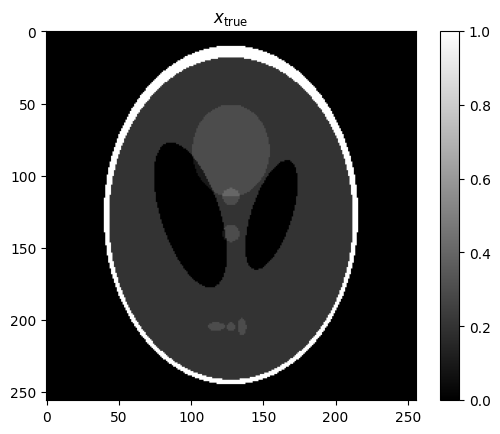

In [3]:
plt.imshow(x_true.reshape((nx,ny)), cmap=CMAP)
plt.title("$x_{\\text{true}}$")
plt.colorbar()
plt.show()

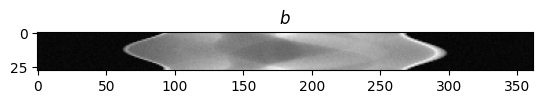

In [4]:
plt.imshow(b_noisy_shaped, cmap=CMAP)
plt.title("$b$")
plt.show()

# Setup prior

In [5]:
# Set method
Lmat = jlinops.build_neumann2d_sparse_matrix(img_shape)
L = jlinops.Neumann2D(img_shape)

# # Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     delta = 1e-15
#     for j in range(10):
#         try:
#             return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=delta)
#         except:
#             delta *= 10
#     return None

K = np.ones(n)/np.linalg.norm(np.ones(n))
K = jlinops.MatrixLinearOperator(K)


def Lpinv_factory(w, *args, **kwargs):
    return CGWeightedNeumann2DPinvOperatorGPU(img_shape, weights=w, tol=1e-4, *args, **kwargs)


# mm_weight_params_2019 = {
#     "q": 1.0,
#     "tau1": 1e-10,
#     "tau2": 1e-16,
# }

mm2_weight_params = {
    "q": 1.0,
}

mm3_weight_params = {
    "q": 1.0,
}

mm_weight_params = {
    "q": 1.0,
    "epsilon": 1e-4,
}

ias_weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

# Setup solvers

In [6]:
# Build solvers
gks_solver = VanillaGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

mm_gks_solver = MMGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm2_gks_solver = MM2GKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm3_gks_solver = MM3GKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm_fgk_solver = MMFGK(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
mm_gkb_solver = MMGKB(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

ias_gks_solver = IASGKS(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
ias_fgk_solver = IASFGK(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)
ias_gkb_solver = IASGKB(A, L, b_noisy, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)

# Misc
AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b_noisy)

# Run all solvers

In [7]:
# Parameters
method = "dp"
n_its = 50
n_its_recres = 120
restart_dim = 15
recycle_dim = 15
ksparsity = None
lambdah_min = 1e-7
lambdah_max = 1e7
fgk_breakdown_tol = 1e-20

In [8]:
%%capture 

all_v_results = []

# GKS
v_gks_data = gks_solver.solve(n_iter=n_its, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params={},
                                    regparam_kwargs={"eta":1.01})

all_v_results.append( ( "V", "GKS", v_gks_data  ) )


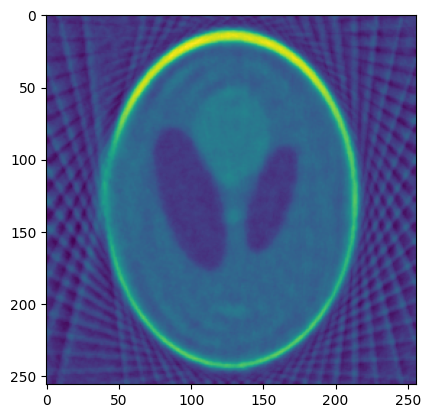

In [9]:
plt.imshow(v_gks_data["x"].reshape(img_shape))

In [10]:
all_mm_results = []

# S-GKS
mm_sgks_data = mm2_gks_solver.solve(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=mm2_weight_params,
                                    regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "S-GKS", mm_sgks_data  ) )

# # Recycled S-GKS
# mm_ressgks_data = mm2_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                     regparam=method, x_true=x_true.flatten(), weight_params=mm2_weight_params,
#                                     regparam_kwargs={"eta":1.01}, restart_dim=None, dim_min=5, dim_max=15)

# all_mm_results.append( ( "MM", "S-GKS (restarted)", mm_ressgks_data  ) )

# # Restarted S-GKS
# mm_recsgks_data = mm2_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                     regparam=method, x_true=x_true.flatten(), weight_params=mm2_weight_params,
#                                     regparam_kwargs={"eta":1.01}, restart_dim=15)

# all_mm_results.append( ( "MM", "S-GKS (recycled)", mm_recsgks_data  ) )


# PS-GKS
mm_psgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params,
                                                 regparam_kwargs={"eta":1.01})

all_mm_results.append( ( "MM", "PS-GKS", mm_psgks_data  ) )


# # Restarted PS-GKS
# mm_respsgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                  regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params, restart_dim=restart_dim,
#                                                  regparam_kwargs={"eta":1.01})

# all_mm_results.append( ( "MM", "PS-GKS (restarted)", mm_respsgks_data  ) )


# # Recycled PS-GKS
# mm_recpsgks_data = mm_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=v_gks_data["x"], lambdah0=v_gks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                  regparam=method, x_true=x_true.flatten(), weight_params=mm_weight_params, dim_max=recycle_dim, dim_min=5,
#                                                  regparam_kwargs={"eta":1.01})

# all_mm_results.append( ( "MM", "PS-GKS (recycled)", mm_recpsgks_data  ) )


# # PS-GKB solver
# mm_gkb_data = mm_gkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
#                                                  regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=mm_weight_params,
#                                                  lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                 #  lambdah_min=1e-7, lambdah_max=1e7,
#                                                 #  init_dim=5
#                                                  )
# all_mm_results.append( ( "MM", "PS-GKB", mm_gkb_data  ) )


# # FGK solver
# mm_fgk_data = mm_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
#                                                  regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=mm_weight_params, refresh_basis=False, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                 #  lambdah_min=1e-7, lambdah_max=1e7,
#                                                 #  init_dim=5
#                                                  )

# all_mm_results.append( ( "MM", "FGK", mm_fgk_data  ) )



Augmented basis with initial guess!


10.101981684343228
9.4313263911306
10.228506008585166
11.588327280740897
11.68150150458992
12.453146334941561
12.34173284222929
12.811124401931338
13.225053463360075
13.919013194874992
14.505685407137848
14.574253764712452
14.579461574145215
14.890902488540512
14.920138200921423
14.659868719362779
14.431410860827796
14.335409326407186
14.128813272866278
14.020563148213773
13.912219700345954
13.874646964768743
13.774805993153032
13.713725015414528
13.67498519339797
13.65075152938642
13.599289329007016
13.576123717138739
13.585246296545103
13.593577954965152
13.560918079070074
13.541864769227272
13.540826292736226
13.527440314361078
13.502391073126061
13.502355016347604
13.496583523157554
13.476234476013145
13.477995792408512
13.475650396211655
13.462460849908558
13.465540279590595
13.462886340519415
13.458742374963716
13.461298360015478
13.460721049097238
13.46027058916964
13.45989912040036
13.460031588872967
13.46072596990761
Augmented basis with initial guess!


/home/jlindbloom/Github/IRLS_prec_GSBL/msolver.py:888: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
3.5312109682987396
8.01288722254164
9.348775091752428
10.075760933995559
11.109273980493906
11.818315879165906
11.482344010741283
11.639211107073034
11.862120315960937
12.712452912720453
13.348644535041558
14.011831819276512
14.572992749057063
14.730773627580538
15.30133886841765
14.91983369749029
14.945136823324216
15.183513128869464
15.177538245040349
15.630282700884683
15.7161743464129
15.72848540632699
15.820713961184286
15.805083928236193
15.906379609298238
15.86640453993395
15.94673670957938
15.990464486107529


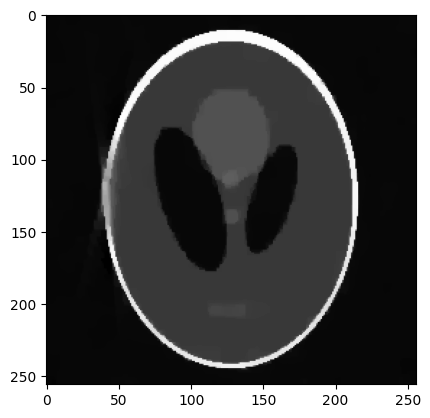

In [12]:
plt.imshow(mm_psgks_data["x"].reshape(img_shape), cmap="gray")
plt.show()

In [13]:
all_ias_results = []

# S-GKS
ias_sgks_data = ias_gks_solver.solve(n_iter=n_its, init_dim=5, x0=mm_psgks_data["x"], lambdah0=mm_psgks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "S-GKS", ias_sgks_data  ) )

# Restarted S-GKS
ias_ressgks_data = ias_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=mm_psgks_data["x"], lambdah0=mm_psgks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=None, dim_min=5, dim_max=15)

all_ias_results.append( ( "IAS", "S-GKS (restarted)", ias_ressgks_data  ) )

# Recycled S-GKS
ias_recsgks_data = ias_gks_solver.solve(n_iter=n_its_recres, init_dim=5, x0=mm_psgks_data["x"], lambdah0=mm_psgks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                    regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                    regparam_kwargs={"eta":1.01}, restart_dim=15)

all_ias_results.append( ( "IAS", "S-GKS (recycled)", ias_recsgks_data  ) )


# PS-GKS
ias_psgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=mm_psgks_data["x"], lambdah0=mm_psgks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params,
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS", ias_psgks_data  ) )


# Restarted PS-GKS
ias_respsgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=mm_psgks_data["x"], lambdah0=mm_psgks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params, restart_dim=restart_dim,
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS (restarted)", ias_psgks_data  ) )


# Recycled PS-GKS
ias_recpsgks_data = ias_gks_solver.solve_with_priorconditioning(n_iter=n_its, init_dim=5, x0=mm_psgks_data["x"], lambdah0=mm_psgks_data["lambdah"], lambdah_min=lambdah_min, lambdah_max=lambdah_max,
                                                 regparam=method, x_true=x_true.flatten(), weight_params=ias_weight_params, dim_max=recycle_dim, dim_min=5,
                                                 regparam_kwargs={"eta":1.01})

all_ias_results.append( ( "IAS", "PS-GKS (recycled)", ias_recpsgks_data  ) )


# # PS-GKB solver
# ias_gkb_data = ias_gkb_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
#                                                  regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=ias_weight_params,
#                                                  lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                 #  lambdah_min=1e-7, lambdah_max=1e7,
#                                                 #  init_dim=5
#                                                  )
# all_ias_results.append( ( "IAS", "PS-GKB", ias_gkb_data  ) )


# # FGK solver
# ias_fgk_data = ias_fgk_solver.solve(n_iter=n_its, x0=None, lambdah0=None, breakdown_tol=fgk_breakdown_tol,
#                                                  regparam=method, x_true=x_true.flatten(), ksparsity=None, weight_params=ias_weight_params, refresh_basis=False, lambdah_min=lambdah_min, lambdah_max=lambdah_max,
#                                                 #  regparam_kwargs={"eta":1.01},
#                                                 #  lambdah_min=1e-7, lambdah_max=1e7,
#                                                 #  init_dim=5
#                                                  )

# all_ias_results.append( ( "IAS", "FGK", ias_fgk_data  ) )



Augmented basis with initial guess!


5.923816888932866
66.37145879645352
170.89004443797106
301.42081329396365
432.6682834769037
606.7302259358657
817.3981247522253
991.0815313223457
1077.910650309128
998.9589992423029
872.0887151080481
790.7325386718203
737.0238096672838
702.8944019711083
679.0993766467302
666.7226353635384
671.8423351351279
669.5403624030764
667.7932468975247
667.9220154397044
668.7762792630685
666.4335192518995
664.4941948004108
662.0149562987851
658.9443099447923
655.5945413780846
653.2050416308158
650.6705422422372
648.9781334700182
650.6698843791086
653.4596158350977
655.3415182931423
658.4796296903475
661.328438416709
665.0378885999389
667.7566214929357
670.2386697852626
672.5467383159187
674.6364455097562
676.7300552498724
678.6569975512675
680.0854327001067
681.0314034335496
681.7205622735557
682.0316475833198
681.8440948304885
682.054416349507
682.0291286501853
681.6920269800812
681.4382053361796
Augmented basis with initial guess!


5.923816888932866
66.37145879645352
170.89004443797106
301.42081329396365
432.6682834769037
606.7302259358657
817.3981247522253
991.0815313223457
1077.910650309128
998.9589992423029
872.0887151080481
790.7325386718203
737.0238096672838
702.8944019711083
679.0993766467302
666.7226353635384
671.8423351351279
669.5403624030764
667.7932468975247
667.9220154397044
668.7762792630685
666.4335192518995
664.4941948004108
662.0149562987851
658.9443099447923
655.5945413780846
653.2050416308158
650.6705422422372
648.9781334700182
650.6698843791086
653.4596158350977
655.3415182931423
658.4796296903475
661.328438416709
665.0378885999389
667.7566214929357
670.2386697852626
672.5467383159187
674.6364455097562
676.7300552498724
678.6569975512675
680.0854327001067
681.0314034335496
681.7205622735557
682.0316475833198
681.8440948304885
682.054416349507
682.0291286501853
681.6920269800812
681.4382053361796
678.1615297808825
676.2193282629493
672.9278109100178
669.4785916503355
665.5502861189216
661.452763

5.923816888932866
66.37145879645352
170.89004443797106
301.42081329396365
432.6682834769037
606.7302259358657
817.3981247522253
991.0815313223457
1077.910650309128
1118.1481716405847
1660.7225041438796
1336.3426972944783
6191.049560557362
13801.793329370643
10312.922612611643
3764.5673259709965
3288.2505294960556
3879.17458435704
4378.587816245454
3950.445292279841
2839.0842609738743
2269.5386592460145
2012.3721448710276
1829.3548471932165
2134.4503723755915
2729.6898757810254
2287.558392608738
2614.188591067453
2599.384892941205
2518.0662556155257
2604.450637604525
2691.1481252409685
2705.7203460323904
2701.056899571963
2686.0807786401488
2684.608757600826
2703.012753474914
2720.7029551727755
2951.848337601746
2639.1906127151
3106.5982656608926
3409.646116976596
3374.91371536418
3020.331192281954
2679.429304871407
2583.338035398029
2587.068121033759
2603.8337841920206
2633.886536793363
2637.693600752262
2620.9873832911
2598.745950933886
2573.3817203013377
1489.9130216570227
2049.11339

1e-07


/home/jlindbloom/Github/IRLS_prec_GSBL/msolver.py:888: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
5.468812212897735
1e-07
8.01023079437075
1e-07
10.169943228373185
1e-07
11.118833682404357
1e-07
11.964823556852226
1e-07
12.757263575204897
1e-07
13.191231808287037
29.261105522622415
1e-07
13.243293575645911
38.735291918453946
37.567993189140104
34.58727836803033
55.70947558957047
95.14252234682189
109.24839198663314
116.225764129973
Augmented basis with initial guess!


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
Augmented basis with initial guess!


1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
1e-07
5.468812212897735
1e-07
8.01023079437075
1e-07
10.169943228373185
1e-07
11.118833682404357
1e-07
11.964823556852226
1e-07
12.757263575204897
1e-07
13.191231808287037
29.261105522622415
1e-07
13.243293575645911
38.735291918453946
37.567993189140104
34.58727836803033
55.70947558957047
95.14252234682189
109.24839198663314
116.225764129973


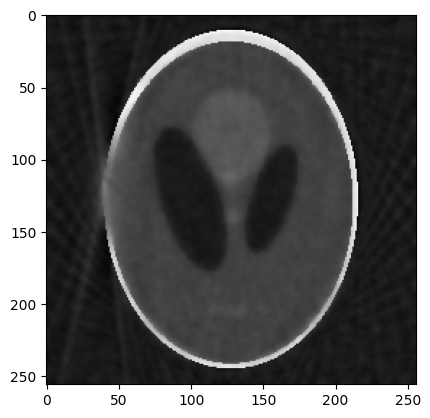

In [15]:
plt.imshow( ias_psgks_data["x"].reshape(img_shape), cmap="gray" )
plt.show()

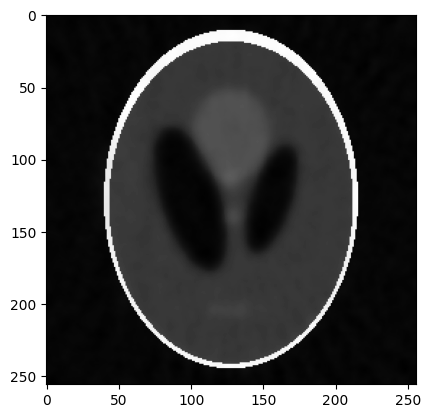

In [12]:
plt.imshow( ias_psgks_data["x"].reshape(img_shape), cmap="gray" )
plt.show()

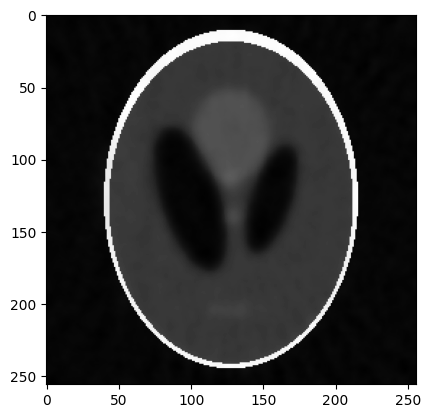

In [13]:
plt.imshow( ias_psgks_data["x"].reshape(img_shape), cmap="gray" )
plt.show()

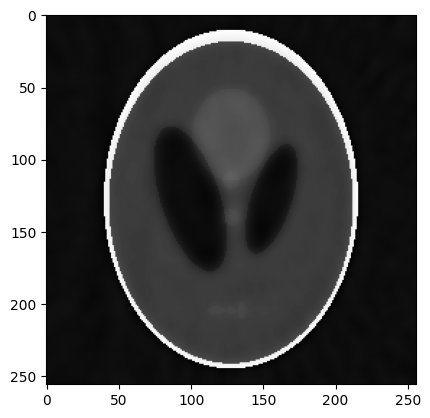

In [14]:
plt.imshow( ias_respsgks_data["x"].reshape(img_shape), cmap="gray" )
plt.show()

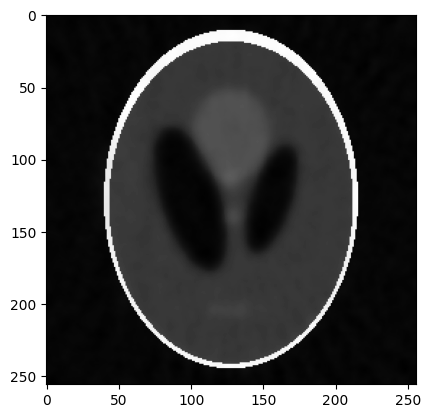

In [15]:
plt.imshow( ias_recpsgks_data["x"].reshape(img_shape), cmap="gray" )
plt.show()

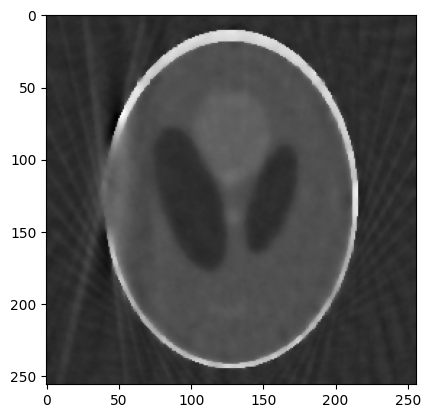

In [18]:
plt.imshow( ias_sgks_data["x"].reshape(img_shape), cmap="gray" )
plt.show()

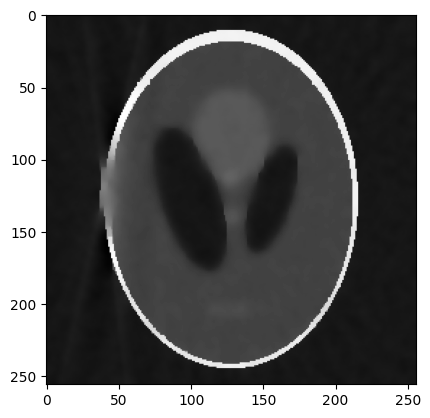

In [19]:
plt.imshow( ias_recsgks_data["x"].reshape(img_shape), cmap="gray" )
plt.show()

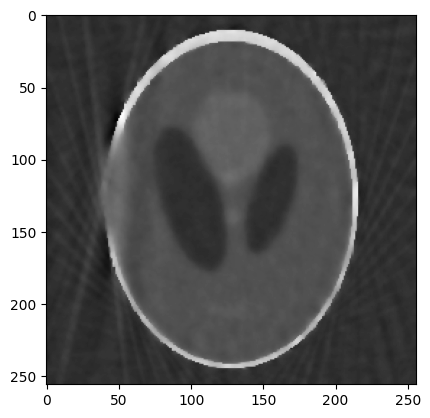

In [20]:
plt.imshow( ias_ressgks_data["x"].reshape(img_shape), cmap="gray" )
plt.show()

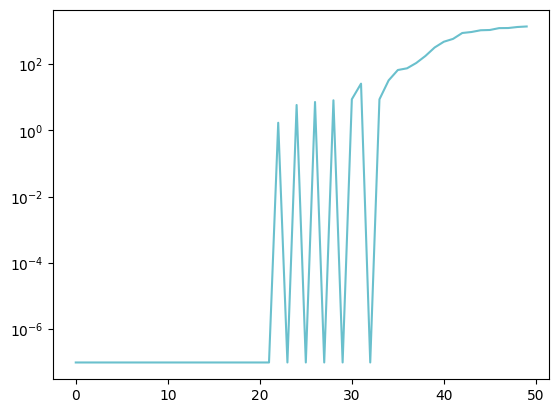

In [16]:
plt.plot(ias_psgks_data["lambda_history"])
plt.semilogy()
plt.show()

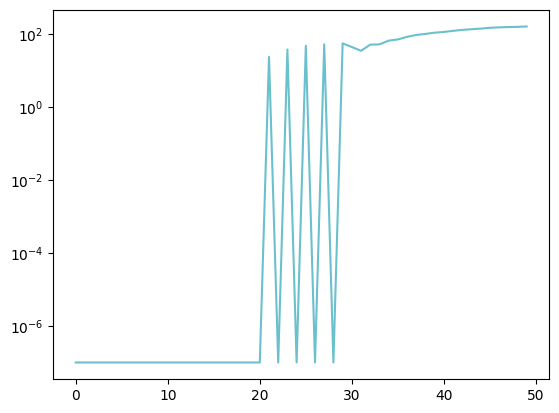

In [22]:
plt.plot(ias_psgks_data["lambda_history"])
plt.semilogy()
plt.show()

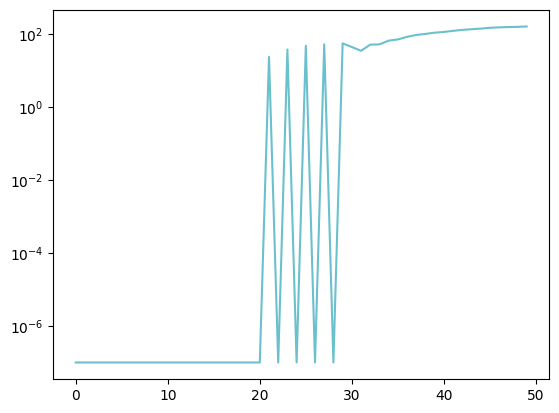

In [23]:
plt.plot(ias_recpsgks_data["lambda_history"])
plt.semilogy()
plt.show()

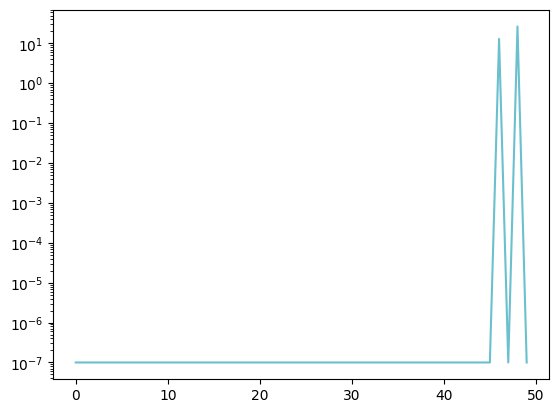

In [24]:
plt.plot(ias_respsgks_data["lambda_history"])
plt.semilogy()
plt.show()

# Save and make tables

In [5]:
v_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "HaarPSI":[], "Gini index": [], "Hoyer index": [], "A matvecs": [], "L matvecs": [], "WLpinv matvecs": []  })

for set in all_v_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ] , "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ]  })
        v_df = pd.concat([v_df, new_df], axis=0)


mm_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

for set in all_mm_results:
        weight_str, method_label, method_data = set
        # print(method_label)
        # print(method_data["rre_history"][-1])
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ],  "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ]  })
        mm_df = pd.concat([mm_df, new_df], axis=0)



ias_df = pd.DataFrame({"Weights":[], "Method":[], "lambdah":[], "RRE":[], "SSIM": [], "Gini index": [], "Hoyer index": []})

for set in all_ias_results:
        weight_str, method_label, method_data = set
        new_df = pd.DataFrame({"Weights":[weight_str], "Method":[method_label], "lambdah":[ method_data["lambda_history"][-1] ], "RRE":[ method_data["rre_history"][-1] ], "SSIM": [ method_data["ssim_history"][-1] ], "HaarPSI":[ method_data["haar_history"][-1] ], "Gini index": [ method_data["gini_indices"][-1] ], "Hoyer index": [ method_data["hoyer_indices"][-1] ],  "A matvecs": [ method_data["tot_matvec_A"] ], "L matvecs": [ method_data["tot_matvec_L"] ], "WLpinv matvecs": [ method_data["tot_matvec_WLpinv"] ]   })
        ias_df = pd.concat([ias_df, new_df], axis=0)



NameError: name 'all_v_results' is not defined

In [6]:
all_df = pd.concat([v_df, mm_df, ias_df])
all_df = all_df.rename(columns={'lambdah': '$\lambda$'})
all_df.to_csv("2d_tomo_shepp_performance_results.csv")
all_df

NameError: name 'mm_df' is not defined

In [15]:
def scientific_to_latex(sci_str):
    # Split the number into base and exponent parts
    sci_str = f"{sci_str:.0e}"
    base, exponent = sci_str.split('e')
    
    # Convert base to integer (since the decimal places can be ignored)
    base = str(int(float(base)))
    
    # Prepare the exponent part, removing the leading "+" if it's a positive exponent
    exponent = exponent.lstrip("+")
    
    # Format the result as a LaTeX string
    latex_str = f"${base}\\cdot10^{{{int(exponent)}}}$"
    
    return latex_str

In [16]:
print( all_df.to_latex(index=False, formatters={'$\lambda$': lambda s: scientific_to_latex(s), 
                                                "RRE": "${:.3f}$", "SSIM": "${:.3f}$", "HaarPSI": "${:.4e}$", 
                                                  "Gini index": "${:.3f}$", "Hoyer index": "${:.3f}$"
                                                    }) )

\begin{tabular}{llrrrrrrrrr}
\toprule
Weights & Method & $\lambda$ & RRE & SSIM & HaarPSI & Gini index & Hoyer index & A matvecs & L matvecs & WLpinv matvecs \\
\midrule
V & GKS & $2\cdot10^{2}$ & $0.418$ & $0.422$ & $9.9661e-01$ & $0.538$ & $0.361$ & 75.000000 & 95.000000 & 0.000000 \\
MM & S-GKS & $1\cdot10^{1}$ & $0.281$ & $0.642$ & $9.9816e-01$ & $0.742$ & $0.688$ & 75.000000 & 96.000000 & 0.000000 \\
MM & S-GKS (restarted) & $1\cdot10^{1}$ & $0.278$ & $0.660$ & $9.9819e-01$ & $0.745$ & $0.692$ & 215.000000 & 306.000000 & 0.000000 \\
MM & S-GKS (recycled) & $1\cdot10^{1}$ & $0.369$ & $0.488$ & $9.9713e-01$ & $0.663$ & $0.540$ & 222.000000 & 313.000000 & 0.000000 \\
MM & PS-GKS & $1\cdot10^{1}$ & $0.239$ & $0.725$ & $9.9856e-01$ & $0.865$ & $0.763$ & 1241.000000 & 33.000000 & 1270.000000 \\
MM & PS-GKS (restarted) & $1\cdot10^{1}$ & $0.239$ & $0.725$ & $9.9856e-01$ & $0.865$ & $0.763$ & 1241.000000 & 33.000000 & 1270.000000 \\
MM & PS-GKS (recycled) & $1\cdot10^{1}$ & $0.239$ & $0.7

# Reconstruction plots

In [17]:
from skimage.metrics import structural_similarity